# Solution: Automated EDA — Swiss EV Charging Stations

In [2]:
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Task 1
df = pd.read_csv('../data/ev_charging_stations.csv')
print('Shape:', df.shape)
df.head(3)

Shape: (2442, 15)


,evse_id,station_name,street,city,postal_code,lat,lon,power_kw,power_type,amperage,voltage,plug_type,is_open_24h,renewable_energy,auth_mode
0,CH*CCI*E22078,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.23432,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic
1,CH*CCI*E22076,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.23432,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic
2,CH*CCI*E22079,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.23432,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic


### Task 2 — `sweetviz` report

In [3]:
import logging
# Silence 'findfont: Failed to find font ... Roboto' messages emitted while sweetviz renders
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

try:
    import sweetviz as sv
    report = sv.analyze(df)
    report.show_html('ev_sweetviz_report.html', open_browser=False)
    print('Report saved to ev_sweetviz_report.html')
except ImportError:
    print('sweetviz not installed. Run: pip install sweetviz')

                                             |          | [  0%]   00:00 -> (? left)

Report ev_sweetviz_report.html was generated.
Report saved to ev_sweetviz_report.html


### Task 3 — Lightweight `quick_profile()`

=== Quick Profile ===
Rows: 2,442  |  Columns: 15
Missing values:
lat         0
lon         0
power_kw    0
amperage    0
voltage     0

Duplicates: 0

Descriptive statistics:


,lat,lon,power_kw,amperage,voltage
count,2442.00,2442.00,2442.00,2442.00,2442.00
mean,46.95,7.05,50.50,111.22,272.71
std,0.67,3.53,77.31,199.58,76.33
min,45.98,-15.00,4.00,16.00,150.00
25%,46.32,6.55,22.00,32.00,230.00
50%,46.95,7.44,22.00,32.00,230.00
75%,47.36,8.54,22.00,50.00,230.00
max,50.00,10.33,400.00,1000.00,1000.00


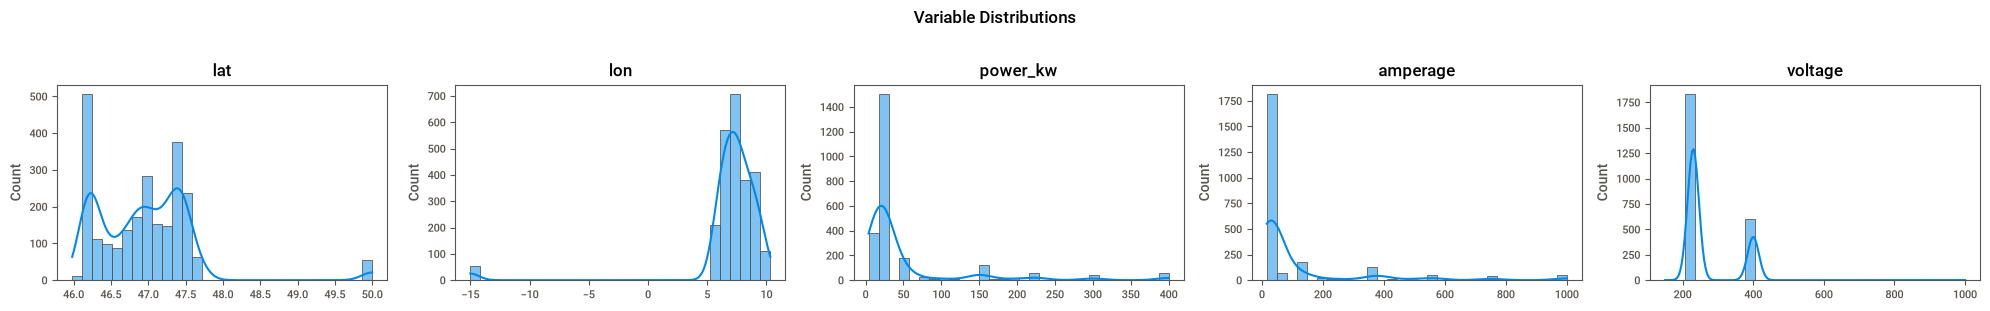

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

def quick_profile(df: pd.DataFrame, max_cols: int = 10) -> None:
    num_cols = df.select_dtypes(include='number').columns[:max_cols]
    print('=== Quick Profile ===')
    print(f'Rows: {len(df):,}  |  Columns: {df.shape[1]}')
    print(f'Missing values:\n{df[num_cols].isnull().sum().to_string()}')
    print(f'\nDuplicates: {df.duplicated().sum()}')
    print('\nDescriptive statistics:')
    display(df[num_cols].describe().round(2))
    n = len(num_cols)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 3))
    if n == 1:
        axes = [axes]
    for ax, col in zip(axes, num_cols):
        sns.histplot(df[col].dropna(), bins=30, kde=True, ax=ax)
        ax.set_title(col)
        ax.set_xlabel('')
    fig.suptitle('Variable Distributions', fontsize=12, y=1.02)
    plt.tight_layout()
    plt.show()

quick_profile(df)

### Task 4 — Answer the questions

In [5]:
# Which variable has the highest skewness?
num_cols = ['power_kw', 'amperage', 'voltage']
skew = df[num_cols].skew().sort_values(ascending=False)
print('Skewness:')
print(skew.round(3))
print(f'\nHighest skewness: {skew.index[0]} ({skew.iloc[0]:.2f})')
print('power_kw is strongly right-skewed: most stations provide 22 kW, but a few fast-chargers reach 400 kW.')

Skewness:
power_kw    3.002
amperage    2.913
voltage     1.726
dtype: float64

Highest skewness: power_kw (3.00)
power_kw is strongly right-skewed: most stations provide 22 kW, but a few fast-chargers reach 400 kW.


In [6]:
# Are there any missing values or duplicates?
print('Missing values per column:')
print(df.isnull().sum())
print(f'\nDuplicate rows: {df.duplicated().sum()}')
print('\nNo missing values and no duplicates in this dataset.')

Missing values per column:
evse_id             0
station_name        0
street              0
city                0
postal_code         0
lat                 0
lon                 0
power_kw            0
power_type          0
amperage            0
voltage             0
plug_type           0
is_open_24h         0
renewable_energy    0
auth_mode           0
dtype: int64

Duplicate rows: 0

No missing values and no duplicates in this dataset.


In [7]:
# Which two variables are most strongly correlated?
corr = df[num_cols].corr(method='pearson')
print('Pearson correlation matrix:')
print(corr.round(3))

# Extract off-diagonal maximum
import numpy as np
mask = np.triu(np.ones(corr.shape), k=1).astype(bool)
upper = corr.where(mask)
max_pair = upper.stack().abs().idxmax()
max_val = upper.loc[max_pair]
print(f'\nStrongest correlation: {max_pair[0]} vs. {max_pair[1]} (r = {max_val:.3f})')
print('Higher charging power requires higher current (P = U x I).')

Pearson correlation matrix:
          power_kw  amperage  voltage
power_kw     1.000     0.997    0.672
amperage     0.997     1.000    0.680
voltage      0.672     0.680    1.000

Strongest correlation: power_kw vs. amperage (r = 0.997)
Higher charging power requires higher current (P = U x I).


## Jupyter notebook --footer info--
(please always provide this at the end of each notebook)

In [8]:
import os, platform, socket
from platform import python_version
from datetime import datetime
print('------------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python Version:', python_version())
print('------------------------------------')

------------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-11-08 22:57:12
Python Version: 3.11.17
------------------------------------
